<a href="https://colab.research.google.com/github/ibader85/PredictiveAnalytics/blob/main/24_Hierarchical_Clustering_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

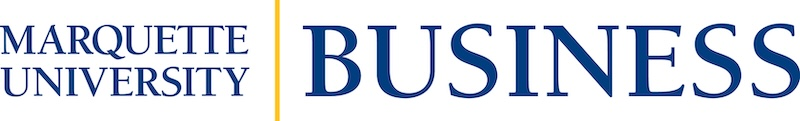

# BUAN 3065: Unlocking Business Insights with Predictive Analytics
# Hierarchical Clustering Using Python

Instructor: Dr. Badar Al Lawati

**Disclaimer:** the content in this notebook is based on the content in Chapter 14 of Business Analytics by Sanjiv Jaggia, Alison Kelly, Kevin Lertwachara and Leida Chen. ISBN10: 126692602X | ISBN13: 9781266926020

Dataset relating to the crime rate (crimes
per 100,000 residents), the poverty rate (in %), and the median income (in $1,000s) for 41 cities in the United States

In [1]:
# Import the dataset

import pandas as pd
myData = pd.read_excel('/content/Cities.xlsx')
myData.head()

,City,Crime,Poverty,Income
0,Barnstable,710.6,3.8,58.422
1,Boston,1317.7,16.7,48.729
2,Brockton,1224.4,9.2,50.752
3,Cambridge,491.6,10.3,58.457
4,Fall River,1271.3,15.5,36.291


In [2]:
from sklearn.preprocessing import scale
myData_std = scale(myData.drop('City', axis = 1))

To perform hierarchical clustering, we use SciPy’s linkage
function. The first option in the linkage function refers to the data
set to be clustered

In addition to a data set, the linkage function
can also work with a condensed distance matrix

A condensed
distance matrix is a more compact representation of pairwise
distances

It is a one-dimensional array that stores only the unique
pairwise distances between points or objects. The second option,
metric, refers to the distance calculation method

In this example,
we use the Euclidean distance. Other distance calculation
methods are also available

For example, if all the variables are
categorical, for computing the matching and Jaccard coefficients,
you can use metric = ‘matching’ and metric = ‘jaccard’, respectively.
The last option, method, specifies the clustering method

In [3]:
from scipy.cluster.hierarchy import linkage
HC = linkage(myData_std, metric = 'euclidean', method =
'ward')

We first create a subplot that is 12
inches in width and 6 inches in height.

We then generate a
dendrogram plot based on the hierarchical clustering structure
provided in HC.

Finally, we display the dendrogram plot on the
screen using the show function

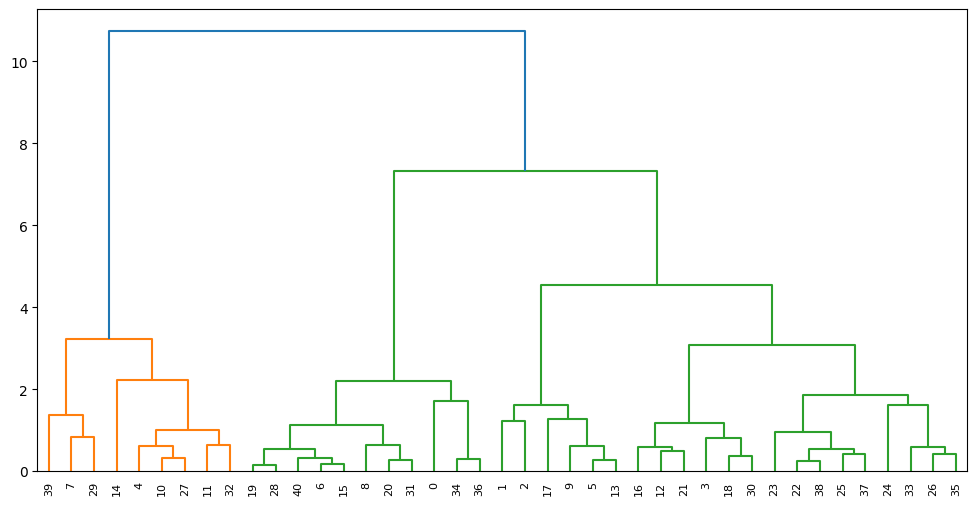

In [4]:
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt
plt.subplots(figsize = (12, 6))
dendrogram(HC)
plt.show()

Based on inspection of the dendrogram, we can determine the
number of clusters.

The dendrogram suggests a three-cluster
structure would create three groups of cities that are distinctive
from one another.

We can visualize the three-cluster structure
using a dendrogram plot.

In the dendrogram function, we use p =
3 to specify that only three clusters will be shown when
truncating the dendrogram.

The truncate_mode = ‘lastp’ option
specifies that the last p (in this case, 3) clusters should be
displayed.

Because hierarchical clustering clusters sequentially
based on distance, the last few clusters are the ones with the
farthest distances from one and another, usually displayed at the
top of a dendrogram

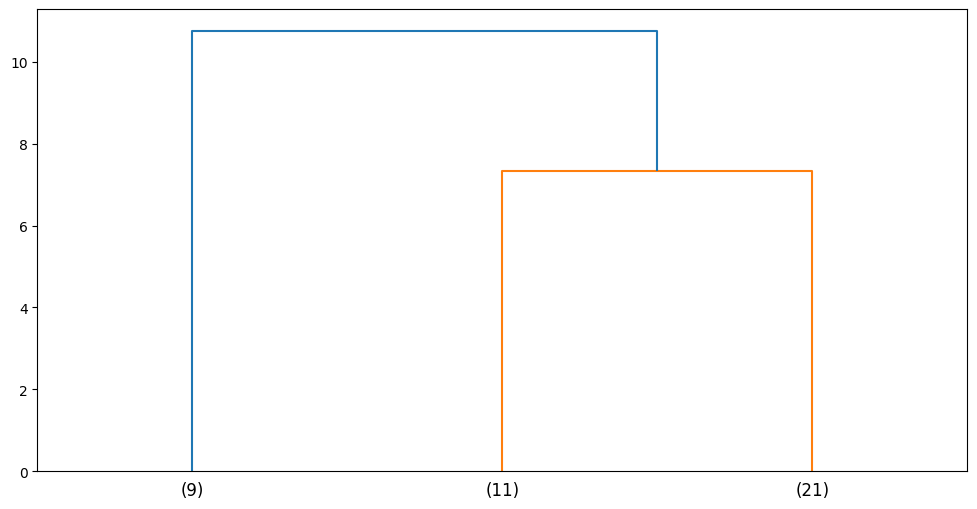

In [5]:
plt.subplots(figsize = (12, 6))
dendrogram(HC, p = 3, truncate_mode = 'lastp')
plt.show()

In [6]:
# We use the cut_tree function to create three clusters in the
# clustering structure, HC, and append the cluster memberships to
# the original data frame, myData, in a new column named Cluster

from scipy.cluster.hierarchy import cut_tree
myData['Cluster'] = cut_tree(HC, n_clusters = 3)
myData.head()
myData.tail()

,City,Crime,Poverty,Income,Cluster
36,Stamford,294.6,5.0,72.315,0
37,Waterbury,399.5,16.7,39.115,1
38,Pawtucket,353.0,14.6,40.299,1
39,Providence,680.5,23.1,35.264,2
40,Warwick,139.7,3.9,59.445,0


In [7]:
# To obtain the summary statistics for the three clusters, we
# concatenate the information about the size of each cluster and
# average values of the variables into a new data frame

pd.concat([myData.groupby('Cluster').size().rename('Count'), myData.groupby('Cluster').mean(numeric_only=True)], axis = 1)

,Count,Crime,Poverty,Income
Cluster,,,,
0,11,235.900000,5.509091,61.392636
1,21,544.219048,12.276190,45.642762
2,9,1160.544444,21.455556,35.055222
